# EMQA_L4_horizon

**The square-root-of-time rule overstates the 10-day risk**

Energy Markets Quantitative Analysis (EMQA), Lecture 4 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L4/EMQA_L4_horizon/EMQA_L4_horizon.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter, NullFormatter

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5,
    'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}   # fixed colour per zone / series


def legend_bottom(fig, ncol=4):
    # one legend for the whole figure, centred under the axes
    handles, labels = [], []
    for ax in fig.axes:
        for h, l in zip(*ax.get_legend_handles_labels()):
            if l not in labels:
                handles.append(h)
                labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0),
               frameon=False, handlelength=2.0, columnspacing=1.2)


def show(key, value):
    # prints a number shown on the slide, under its key in lectures/L4/L4_numbers.json
    print(f'{key:<28} = {value}')


def d(ts):
    return pd.Timestamp(ts).strftime('%Y-%m-%d')

In [3]:
# daily day-ahead base prices (mean of all market time units of the CET/CEST delivery day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
START = pd.Timestamp('2015-01-01')
END = pd.Timestamp('2026-10-31')           # cut-off of Lecture 4: last complete month of the download
CAL = pd.date_range(START, END, freq='D')
P = PD[['RO', 'DE_LU']].reindex(CAL)           # full calendar: missing days stay missing
X = P.diff()                           # daily change X_t = P_t - P_{t-1}; a change next to a gap is missing
print('daily prices', d(START), 'to', d(END), '| missing days in Romania:', int(P['RO'].isna().sum()))

daily prices 2015-01-01 to 2026-10-31 | missing days in Romania: 5


## Scaling the VaR to h days

If daily changes were independent, $\mathrm{VaR}_h=\sqrt h\,\mathrm{VaR}_1$. Electricity prices revert to their mean, so the empirical ratio $q_{0.99}(P_{t+h}-P_t)/q_{0.99}(P_{t+1}-P_t)$ grows much more slowly.

In [4]:
HOR, VR = {}, {}
for z in ['RO', 'DE_LU']:
    p = P[z]
    q1 = (p.shift(-1) - p).dropna().quantile(0.99)
    v1 = (p.shift(-1) - p).var()
    HOR[z] = {h: (p.shift(-h) - p).dropna().quantile(0.99) / q1 for h in range(1, 21)}
    VR[z] = {h: (p.shift(-h) - p).var() / (h * v1) for h in range(1, 21)}
show('horizon.ro10', round(HOR['RO'][10], 2))
show('horizon.de10', round(HOR['DE_LU'][10], 2))
show('horizon.sqrt10', round(np.sqrt(10), 2))
show('horizon.vr10_ro', round(VR['RO'][10], 2))
show('horizon.ac1_ro', round(X['RO'].autocorr(1), 3))
show('horizon.ac7_ro', round(X['RO'].autocorr(7), 3))

horizon.ro10                 = 1.72
horizon.de10                 = 1.75
horizon.sqrt10               = 3.16
horizon.vr10_ro              = 0.33
horizon.ac1_ro               = -0.076
horizon.ac7_ro               = 0.474


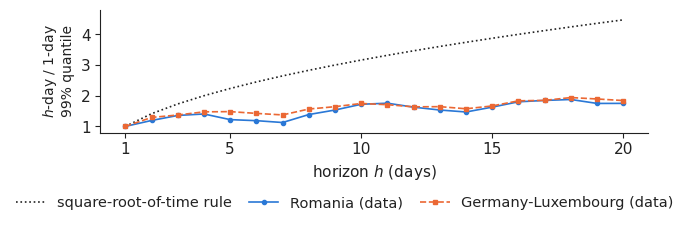

In [5]:
fig, ax = plt.subplots(figsize=(6.4, 2.3))
hs = list(range(1, 21))
ax.plot(hs, np.sqrt(hs), color='#222222', ls=':', lw=1.2, label='square-root-of-time rule')
ax.plot(hs, [HOR['RO'][h] for h in hs], color=PAL['RO'], marker='o', ms=3, lw=1.2, label='Romania (data)')
ax.plot(hs, [HOR['DE_LU'][h] for h in hs], color=PAL['DE_LU'], marker='s', ms=3, lw=1.2, ls='--',
        label='Germany-Luxembourg (data)')
ax.set_xticks([1, 5, 10, 15, 20])
ax.set_xlabel('horizon $h$ (days)')
ax.set_ylabel('$h$-day / 1-day\n99% quantile', fontsize=10)
ax.set_ylim(0.8, 4.8)
legend_bottom(fig, ncol=3)
fig.canvas.draw()
legend_top = max(lg.get_window_extent().y1 for lg in fig.legends) / fig.dpi
fig.tight_layout(rect=(0, max(legend_top - 0.08, 0.05) / fig.get_figheight(), 1, 1))
plt.savefig('horizon.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()